In [2]:
import pandas as pd
import numpy as np

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score,balanced_accuracy_score,precision_score,recall_score,
f1_score,roc_auc_score,average_precision_score,confusion_matrix,ConfusionMatrixDisplay)

import joblib

In [4]:
orders = pd.read_csv("../data/processed/orders_cleaned.csv")

In [5]:
print("Shape:", orders.shape)
orders.head()

Shape: (148528, 6)


,order_date,sales_qty,sales_amount,currency,user_id,restaurant_id
0,2017-10-10,100,41241,INR,49226,567335.0
1,2018-04-06,1,875,INR,5321,158203.0
2,2018-04-11,1,583,INR,21343,187912.0
3,2018-06-18,6,7176,INR,75378,543530.0
4,2017-11-20,59,500,INR,34323,158204.0


CONVERTING DATE TO DATETIME

In [6]:
orders["order_date"] = pd.to_datetime(orders["order_date"])

print("Date range:")
print("Start:", orders["order_date"].min())
print("End:", orders["order_date"].max())

Date range:
Start: 2017-10-04 00:00:00
End: 2020-06-26 00:00:00


DEFINING CHURN CUTTOFF DATE   # USING DECEMBER 31,2019 AS THE CUTOFF

In [7]:
cutoff_date = pd.Timestamp("2019-12-31")

print("Cutoff date:", cutoff_date)

Cutoff date: 2019-12-31 00:00:00


SPLITING ORDERS INTO HISTORICAL AND FUTURE PERIODS

In [8]:
feature_orders = orders[orders["order_date"] <= cutoff_date].copy()

future_orders = orders[orders["order_date"] > cutoff_date].copy()

print("Historical orders:", feature_orders.shape)
print("Future orders:", future_orders.shape)

Historical orders: (127165, 6)
Future orders: (21363, 6)


CREATING CUSTOMER LEVEL FEATURES

In [9]:
churn_features = feature_orders.groupby("user_id").agg(total_orders=("user_id", "count"),total_spend=("sales_amount", "sum"),
    total_quantity=("sales_qty", "sum"),first_order_date=("order_date", "min"),
    last_order_date=("order_date", "max")).reset_index()

print("Customer feature shape:", churn_features.shape)

churn_features.head()

Customer feature shape: (72069, 6)


,user_id,total_orders,total_spend,total_quantity,first_order_date,last_order_date
0,1,2,1672,5,2017-12-12,2018-11-14
1,2,3,4061,7,2018-02-13,2018-08-03
2,3,1,21542,500,2019-05-15,2019-05-15
3,4,1,102,1,2019-02-06,2019-02-06
4,5,2,52047,50,2018-03-02,2018-07-25


CALCULATING AVERAGE ORDER VALUE

In [10]:
churn_features["average_order_value"] = (churn_features["total_spend"] /churn_features["total_orders"])

churn_features[["user_id","total_orders","total_spend","average_order_value"]].head()

,user_id,total_orders,total_spend,average_order_value
0,1,2,1672,836.000000
1,2,3,4061,1353.666667
2,3,1,21542,21542.000000
3,4,1,102,102.000000
4,5,2,52047,26023.500000


CALCULATING RECENCY

In [11]:
churn_features["recency"] = (cutoff_date - churn_features["last_order_date"]).dt.days

churn_features[["user_id","last_order_date","recency"]].head()

,user_id,last_order_date,recency
0,1,2018-11-14,412
1,2,2018-08-03,515
2,3,2019-05-15,230
3,4,2019-02-06,328
4,5,2018-07-25,524


CREATING THE CHURN TARGET

In [12]:
future_customers = set(future_orders["user_id"].unique())

churn_features["churn"] = (~churn_features["user_id"].isin(future_customers)).astype(int)

churn_features[["user_id", "churn"]].head()

,user_id,churn
0,1,1
1,2,1
2,3,1
3,4,1
4,5,1


In [13]:
print(churn_features["churn"].value_counts())

print("\nChurn proportion:")
print(churn_features["churn"].value_counts(normalize=True))

churn
1    58287
0    13782
Name: count, dtype: int64

Churn proportion:
churn
1    0.808767
0    0.191233
Name: proportion, dtype: float64


CREATING ADDITIONAL BEHAVIORAL FEATURES

In [14]:
# Customer tenure
churn_features["tenure_days"] = (churn_features["last_order_date"]- churn_features["first_order_date"]).dt.days

# Active period in months
churn_features["active_months"] = (churn_features["tenure_days"] / 30).round(2)

# Average gap between orders
churn_features["average_days_between_orders"] = np.where(churn_features["total_orders"] > 1,churn_features["tenure_days"] /
                    (churn_features["total_orders"] - 1),0)

# Orders per month
churn_features["orders_per_month"] = np.where(churn_features["active_months"] > 0,churn_features["total_orders"] /
                                              churn_features["active_months"],churn_features["total_orders"])

churn_features[["user_id","tenure_days","active_months","average_days_between_orders","orders_per_month"]].head()

,user_id,tenure_days,active_months,average_days_between_orders,orders_per_month
0,1,337,11.23,337.0,0.178094
1,2,171,5.70,85.5,0.526316
2,3,0,0.00,0.0,1.000000
3,4,0,0.00,0.0,1.000000
4,5,145,4.83,145.0,0.414079


FEATURES AND TARGET

In [15]:
feature_columns = ["total_orders","total_spend","total_quantity","average_order_value","recency","tenure_days",
    "active_months","average_days_between_orders","orders_per_month"]

X = churn_features[feature_columns]
y = churn_features["churn"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

X shape: (72069, 9)
y shape: (72069,)

Features:
['total_orders', 'total_spend', 'total_quantity', 'average_order_value', 'recency', 'tenure_days', 'active_months', 'average_days_between_orders', 'orders_per_month']


TRAIN - TEST - SPLIT

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (57655, 9)
X_test: (14414, 9)
y_train: (57655,)
y_test: (14414,)


**Experiment 1 – baseline. See notebook 10 for the honest evaluation.**

In [17]:
baseline_pred = np.ones(len(y_test), dtype=int)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_balanced_accuracy = balanced_accuracy_score(y_test, baseline_pred)
baseline_precision = precision_score(y_test, baseline_pred)
baseline_recall = recall_score(y_test, baseline_pred)
baseline_f1 = f1_score(y_test, baseline_pred)

print("Everyone-Churns Baseline")
print("Accuracy:", baseline_accuracy)
print("Balanced Accuracy:", baseline_balanced_accuracy)
print("Precision:", baseline_precision)
print("Recall:", baseline_recall)
print("F1 Score:", baseline_f1)

Everyone-Churns Baseline
Accuracy: 0.8087970029138337
Balanced Accuracy: 0.5
Precision: 0.8087970029138337
Recall: 1.0
F1 Score: 0.8942927278306229


LOGISTIC REGRESSION

In [18]:
logistic_model = LogisticRegression(max_iter=1000,class_weight="balanced")

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)

In [19]:
print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, logistic_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, logistic_pred))
print("Precision:", precision_score(y_test, logistic_pred))
print("Recall:", recall_score(y_test, logistic_pred))
print("F1 Score:", f1_score(y_test, logistic_pred))

Logistic Regression
Accuracy: 0.419938948244762
Balanced Accuracy: 0.5042570292524167
Precision: 0.8123934053439454
Recall: 0.3677303139475039
F1 Score: 0.5062887511071745


DECISION TREE

In [20]:
decision_tree_model = DecisionTreeClassifier(random_state=42,class_weight="balanced")

decision_tree_model.fit(X_train, y_train)

decision_tree_pred = decision_tree_model.predict(X_test)

In [21]:
print("Decision Tree")
print("Accuracy:", accuracy_score(y_test, decision_tree_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, decision_tree_pred))
print("Precision:", precision_score(y_test, decision_tree_pred))
print("Recall:", recall_score(y_test, decision_tree_pred))
print("F1 Score:", f1_score(y_test, decision_tree_pred))

Decision Tree
Accuracy: 0.6848203135840155
Balanced Accuracy: 0.4963644255575135
Precision: 0.8073965263976497
Recall: 0.8015096929147366
F1 Score: 0.8044423399767552


RANDOM FOREST

In [22]:
random_forest_model = RandomForestClassifier(n_estimators=100,random_state=42,class_weight="balanced",n_jobs=-1)

random_forest_model.fit(X_train, y_train)

random_forest_pred = random_forest_model.predict(X_test)

In [23]:
print("Random Forest")
print("Accuracy:", accuracy_score(y_test, random_forest_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, random_forest_pred))
print("Precision:", precision_score(y_test, random_forest_pred))
print("Recall:", recall_score(y_test, random_forest_pred))
print("F1 Score:", f1_score(y_test, random_forest_pred))

Random Forest
Accuracy: 0.7691133620091578
Balanced Accuracy: 0.49694015907151595
Precision: 0.8077889447236181
Recall: 0.9376393892605935
F1 Score: 0.8678840809845176


In [24]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

print("KNN Results")
print("Accuracy:", accuracy_score(y_test, knn_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, knn_pred))
print("Precision:", precision_score(y_test, knn_pred, zero_division=0))
print("Recall:", recall_score(y_test, knn_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, knn_pred, zero_division=0))

KNN Results
Accuracy: 0.7773692243652005
Balanced Accuracy: 0.49927328349992195
Precision: 0.8085603681250456
Recall: 0.9495625321667525
F1 Score: 0.8734072349994083


MODEL COMPARISON

In [27]:
model_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "KNN"],
    "Accuracy": [accuracy_score(y_test, logistic_pred),accuracy_score(y_test, decision_tree_pred),accuracy_score(y_test, random_forest_pred),
        accuracy_score(y_test, knn_pred)],
    "Balanced Accuracy": [balanced_accuracy_score(y_test, logistic_pred),balanced_accuracy_score(y_test, decision_tree_pred),
        balanced_accuracy_score(y_test, random_forest_pred),balanced_accuracy_score(y_test, knn_pred)],
    "Precision": [ precision_score(y_test, logistic_pred, zero_division=0), precision_score(y_test, decision_tree_pred, zero_division=0),
            precision_score(y_test, random_forest_pred, zero_division=0), precision_score(y_test, knn_pred, zero_division=0)],
    "Recall": [recall_score(y_test, logistic_pred, zero_division=0),recall_score(y_test, decision_tree_pred, zero_division=0),
        recall_score(y_test, random_forest_pred, zero_division=0),recall_score(y_test, knn_pred, zero_division=0) ],
    "F1 Score": [f1_score(y_test, logistic_pred, zero_division=0),f1_score(y_test, decision_tree_pred, zero_division=0),
        f1_score(y_test, random_forest_pred, zero_division=0),f1_score(y_test, knn_pred, zero_division=0)]})

model_results

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.419939,0.504257,0.812393,0.367730,0.506289
1,Decision Tree,0.684820,0.496364,0.807397,0.801510,0.804442
2,Random Forest,0.769113,0.496940,0.807789,0.937639,0.867884
3,KNN,0.777369,0.499273,0.808560,0.949563,0.873407


5 FOLD CROSS VALIDATION

In [28]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
cv_results = []

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42,
        class_weight="balanced", n_jobs=-1
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}
for name, model in models.items():

    scores = cross_val_score(model,X,y,cv=cv,scoring="f1")

    cv_results.append({"Model": name,"Mean F1": scores.mean(),"Std F1": scores.std()})

    print(name)
    print("Fold F1 Scores:", scores)
    print("Mean F1:", scores.mean())
    print("Std F1:", scores.std())
    print("-" * 40)

cv_results_df = pd.DataFrame(cv_results)

cv_results_df

Logistic Regression
Fold F1 Scores: [0.5968728  0.5669608  0.62236097 0.54403555 0.5932785 ]
Mean F1: 0.5847017234479367
Std F1: 0.026864078738828415
----------------------------------------
Decision Tree
Fold F1 Scores: [0.80475207 0.80375361 0.80132936 0.8012602  0.80377863]
Mean F1: 0.8029747721100984
Std F1: 0.001418357356916859
----------------------------------------
Random Forest
Fold F1 Scores: [0.8683667  0.86706121 0.87097797 0.86913404 0.86953766]
Mean F1: 0.8690155138998177
Std F1: 0.001294464061073755
----------------------------------------
KNN
Fold F1 Scores: [0.87515276 0.87283785 0.87222376 0.87140373 0.87234799]
Mean F1: 0.8727932168039034
Std F1: 0.001266697075861539
----------------------------------------


,Model,Mean F1,Std F1
0,Logistic Regression,0.584702,0.026864
1,Decision Tree,0.802975,0.001418
2,Random Forest,0.869016,0.001294
3,KNN,0.872793,0.001267


In [30]:
random_forest_prob = random_forest_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(
    y_test,
    random_forest_prob
)

pr_auc = average_precision_score(
    y_test,
    random_forest_prob
)

print("Random Forest ROC-AUC:", roc_auc)
print("Random Forest PR-AUC:", pr_auc)

Random Forest ROC-AUC: 0.49225906402126796
Random Forest PR-AUC: 0.8049840260398547


CONFUSION MATRIX

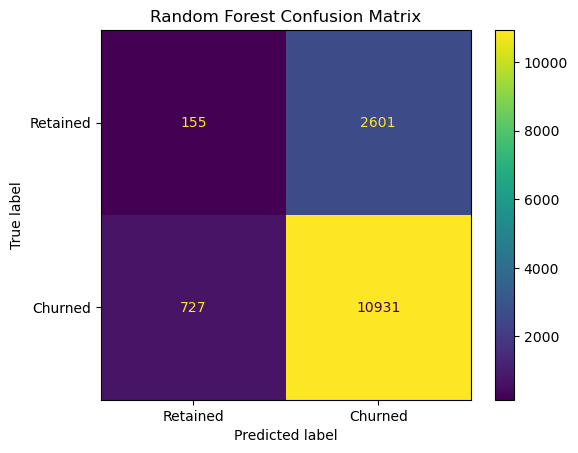

In [31]:
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test,random_forest_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Retained", "Churned"])

disp.plot()

plt.title("Random Forest Confusion Matrix")
plt.show()

FEATURE IMPORTANCE

In [32]:
feature_importance = pd.DataFrame({"Feature": feature_columns,"Importance": random_forest_model.feature_importances_
}).sort_values("Importance", ascending=False)

feature_importance

,Feature,Importance
4,recency,0.349472
3,average_order_value,0.171327
1,total_spend,0.171256
2,total_quantity,0.096354
8,orders_per_month,0.054859
7,average_days_between_orders,0.053023
5,tenure_days,0.049939
6,active_months,0.049804
0,total_orders,0.003966


In [33]:
joblib.dump(random_forest_model,"../models/churn_random_forest.pkl")

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [34]:
from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, balanced_accuracy_score

# Balance only the training data
rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

print("Balanced training distribution:")
print(y_train_under.value_counts())

# Train Random Forest
rf_under = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_under.fit(X_train_under, y_train_under)

# Evaluate on the original test data
rf_under_pred = rf_under.predict(X_test)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_under_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_under_pred, zero_division=0))

print("Balanced Accuracy:",
      balanced_accuracy_score(y_test, rf_under_pred))

Balanced training distribution:
churn
0    11026
1    11026
Name: count, dtype: int64

Confusion Matrix:
[[1398 1358]
 [5965 5693]]

Classification Report:
              precision    recall  f1-score   support

           0       0.19      0.51      0.28      2756
           1       0.81      0.49      0.61     11658

    accuracy                           0.49     14414
   macro avg       0.50      0.50      0.44     14414
weighted avg       0.69      0.49      0.55     14414

Balanced Accuracy: 0.4977955425813727


In [35]:
import numpy as np
from sklearn.metrics import balanced_accuracy_score, recall_score

# Get churn probabilities from the undersampled model
rf_probs = rf_under.predict_proba(X_test)[:, 1]

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    preds = (rf_probs >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Non-churn recall: {recall_score(y_test, preds, pos_label=0):.3f} | "
        f"Churn recall: {recall_score(y_test, preds, pos_label=1):.3f} | "
        f"Balanced accuracy: {balanced_accuracy_score(y_test, preds):.3f}"
    )

Threshold: 0.30 | Non-churn recall: 0.149 | Churn recall: 0.848 | Balanced accuracy: 0.498
Threshold: 0.40 | Non-churn recall: 0.295 | Churn recall: 0.700 | Balanced accuracy: 0.498
Threshold: 0.50 | Non-churn recall: 0.492 | Churn recall: 0.508 | Balanced accuracy: 0.500
Threshold: 0.60 | Non-churn recall: 0.683 | Churn recall: 0.315 | Balanced accuracy: 0.499
Threshold: 0.70 | Non-churn recall: 0.831 | Churn recall: 0.159 | Balanced accuracy: 0.495
